# 05 · Location

**Part 5 of 5** (v2) · Previous: [04 · Results](04_results.ipynb) · Back to the start: [01 · Data and context](01_data_and_context.ipynb)

Backblaze publishes where every drive sits, from the datacenter down to the slot. In this notebook we ask whether
the place where a drive works changes how often it fails, and whether the v1 model detects more failures when it
knows that place. Some vaults do fail far more than chance allows, year after year, but the cause is the drives
they hold (most likely bad manufacturing batches), not the place. Given the vault, the model does not improve: the
S.M.A.R.T. attributes already show those drives failing.

In [1]:
import sys
sys.dont_write_bytecode = True
sys.path.insert(0, "../v2")  # the v2 code is kept apart from the v1
from backblaze_hdd_failure_prediction.figures import use_style
import location_notebook as nb
use_style(); con = nb.connect()

## 1 · Location in the data

If heat, vibration or power differ from one place to another, drives in some places could fail more, and the model
could use that. Before adding the place to the model, we check whether places fail differently once we account for
what they hold. All of this exploration uses training only (Jul 2023 – Jun 2025): validation and test stay for
the ablation.

The table lists the five location columns, how many values each has in training and the largest share of rows
where it is missing in a quarter.

In [2]:
nb.show_location_levels(con)

,what it is,in training,most missing in a quarter
column,,,
datacenter,"a building (sac0, sac2: Sacramento; phx1: Phoenix; iad1: Virginia; ams5: Amsterdam; yyz1: Toronto)",6,8.1 %
cluster_id,a group of vaults,7,0.0 %
vault_id,20 storage servers (pods) that store each file together; a vault is the pair cluster + vault,317 vaults,0.0 %
pod_id,the position of a pod in its vault (one pod: 60 drives),"20 positions, 6,340 pods",0.0 %
pod_slot_num,the slot of the drive in its pod,60 slots,0.5 %


> **Decision**: a vault is the pair cluster + vault, and a missing datacenter is filled from it.
>
> **Why**: the same vault number repeats in different clusters, but every cluster + vault pair sits in a single
> datacenter. The datacenter is missing in up to 8.1 % of the rows of a quarter until Q4 2024; cluster, vault and
> pod are always there.

> **Decision**: compare each place with the failures expected from its drive models.
>
> **Why**: a datacenter full of an old, fragile drive model fails more without the building having anything to do
> with it. Expected failures = the drive-days of each model in that place × that model's failure rate in the whole
> fleet. Observed / expected = 1 means "fails as its drives predict".

The figure gives the annualised failure rate of each datacenter in training, observed and expected from its drive
models; the number on the right is observed / expected.

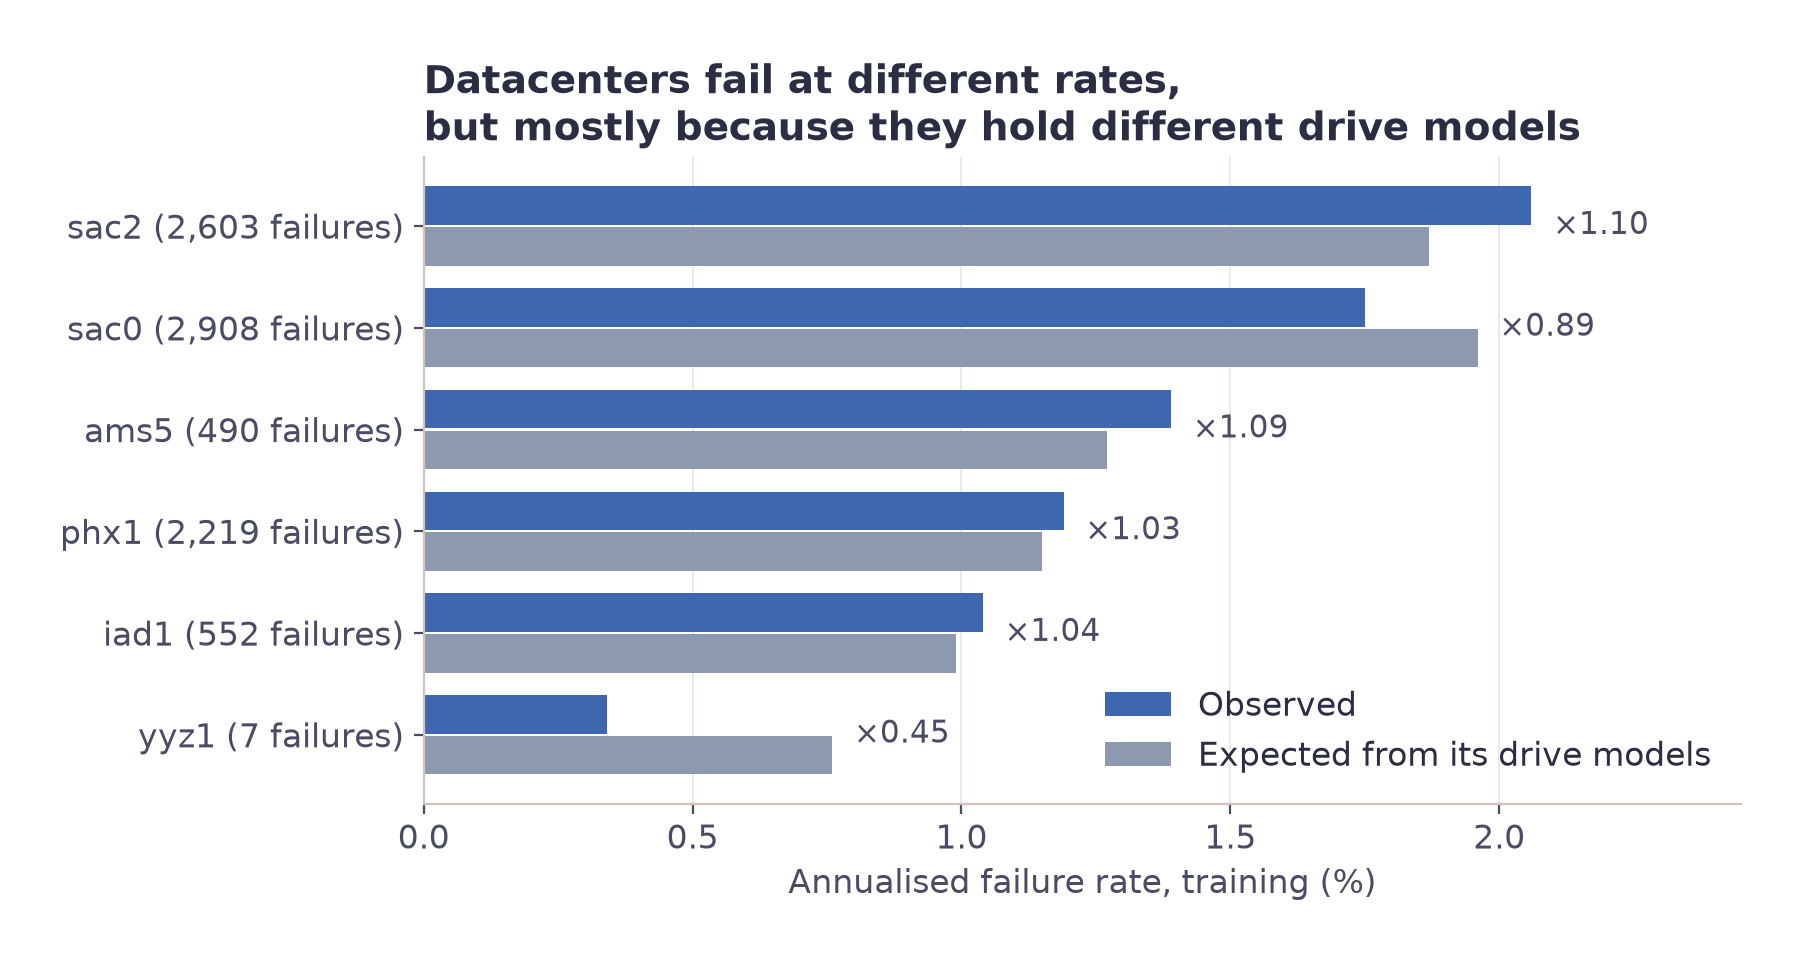

In [3]:
nb.plot_datacenters()

**What we see**

- Raw, the rates differ a lot: sac2 fails twice as often as iad1 (2.06 % against 1.04 % a year).
- Once their drive models are accounted for, the five datacenters with enough failures stay within about ±10 % of
  what their drives predict (0.89 in sac0 to 1.10 in sac2). What sets them apart is mostly what they hold.
- yyz1 (Toronto, open since Dec 2024) has 7 failures and new drives: too little to say anything.

## 2 · A shortcut?

A variable can help in training for a reason that will not repeat: a shortcut. With location, the danger is
maintenance. Backblaze empties old vaults; if the drives pulled out were recorded as failures, as in the MG08
episode but by place, the vault would "predict" decisions of the operators, not failures. If so, emptied vaults
would fail more, and their failures would pile up just before they empty.

The table gives the training failures of the vaults that are there all along, appear or are emptied during training,
against those expected from their drive models; then, for the emptied ones, by days before the vault empties. The
chance margin is roughly 2 / √expected: a ratio that far from 1 can happen by chance alone.

In [4]:
nb.show_shortcut()

,vaults,failures,expected,observed / expected,chance margin ±
group,,,,,
there all along,187,"7,260","7,175.5",1.01,0.02
appear in training,93,"1,062","1,161.9",0.91,0.06
emptied in training,37,457,441.2,1.04,0.10
"emptied, last 30 days",,28,49.4,0.57,0.28
"emptied, 31-90 days",,109,97.8,1.11,0.20
"emptied, 91-180 days",,135,128.3,1.05,0.18
"emptied, more than 180 days",,185,165.8,1.12,0.16


**What we see**

- Emptied vaults fail as their drives predict (1.04 ± 0.10), and there is no pile-up before they empty: in the last
  30 days they fail less (0.57). Drives are pulled before they fail, and a removal is not a failure.
- New vaults fail a little less (0.91 ± 0.06): they are filled with new drives, which fail less than the average of
  their model.
- No sign of a shortcut. One caution for later: some vaults do not exist in training, and a model cannot know them
  (2.9 % of the drive-days of validation, 8.4 % of test).

## 3 · Vaults fail differently, and not by chance

Datacenters are large; a local problem would show in a vault (1,200 drives). But with 317 vaults, some will look
odd by chance alone. We call a vault "outside the margin" when its failures would happen by chance less than 2.5 %
of the time on one side (Poisson, with the expected failures), so chance alone puts about 317 × 2.5 % ≈ 8 above
and 8 below. A real effect gives far more than that, and the same vaults again in the second year.

In [5]:
nb.show_chance()

317 vaults in training. Outside the chance margin (p < 2.5 % on one side):
  above: 44, below: 80  (chance alone: about 8 and 8)
201 vaults with at least 5 expected failures in each training year:
  above in year 1: 27, above again in year 2: 20
  below in year 1: 38, below again in year 2: 14
  correlation of the ratio between years: 0.79


Each dot of the figure is a vault with at least 5 expected failures in each training year: its observed / expected
in the first year against the second. If the differences were chance, the cloud would be round; if something in the
vault lasts, it stretches along the diagonal.

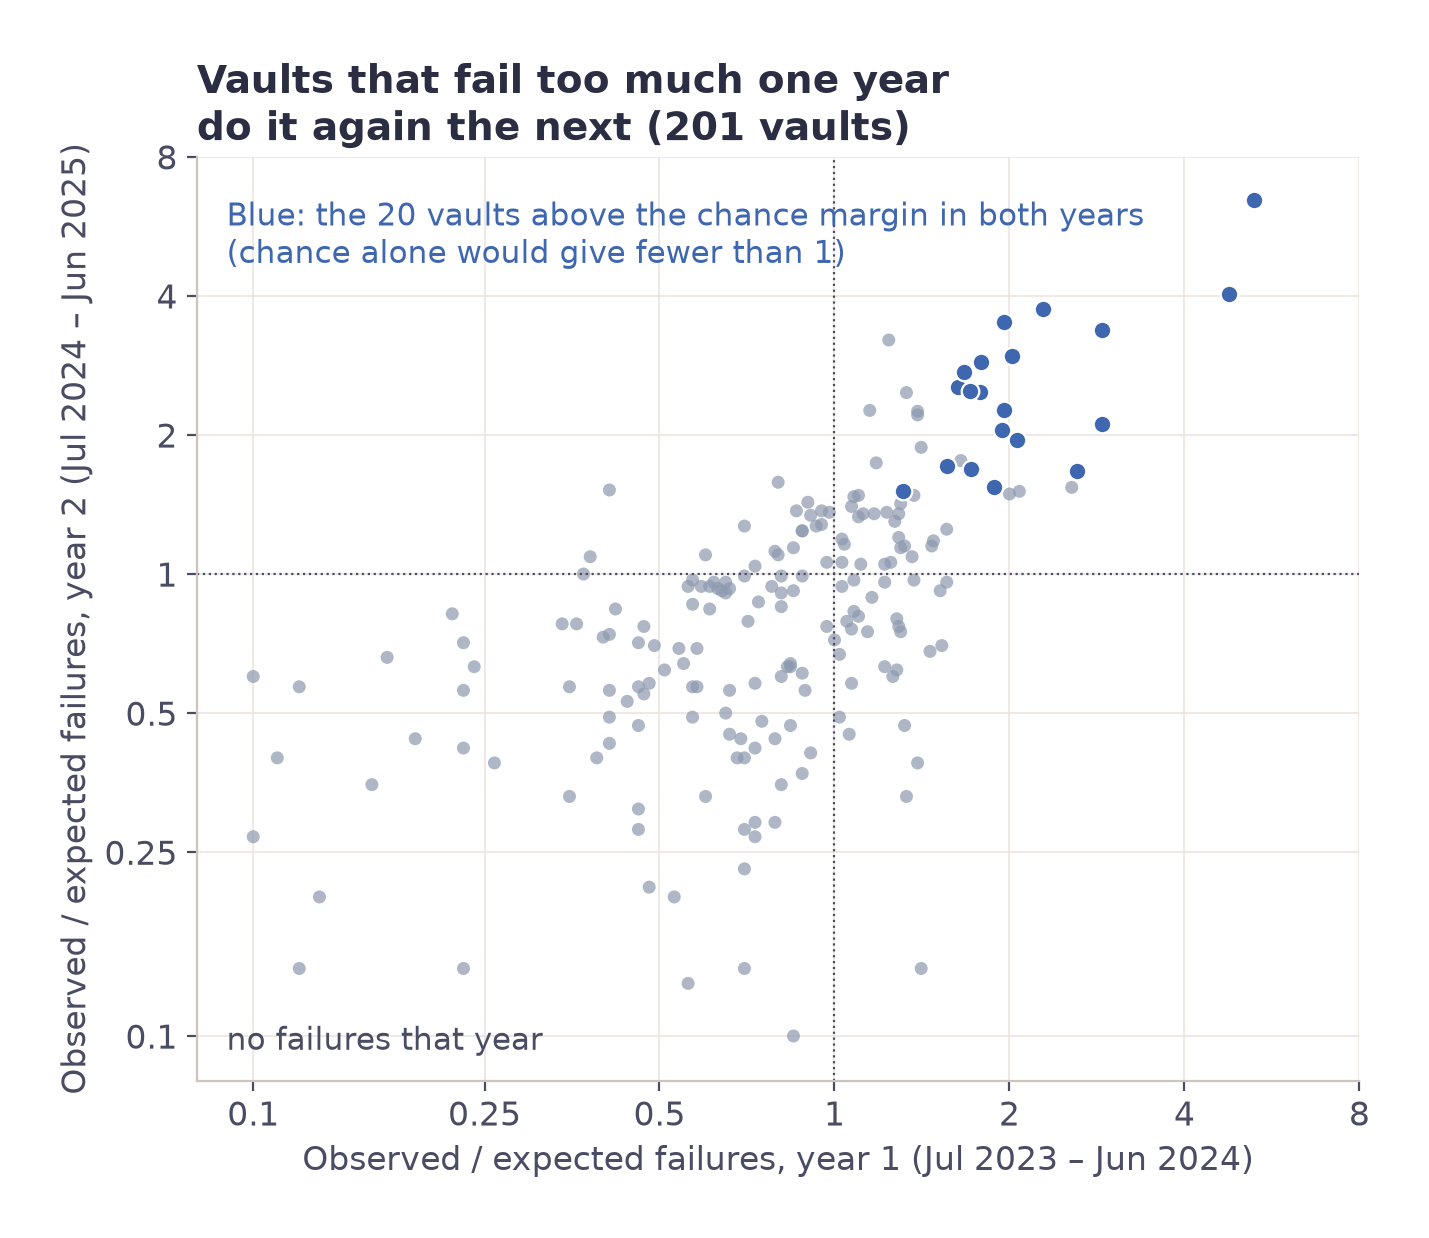

In [6]:
nb.plot_vault_years()

**What we see**

- 124 vaults are outside the margin (44 above, 80 below), where chance gives about 16.
- They repeat: 20 of the 27 vaults above in the first year are above again in the second (chance: fewer than 1),
  and the ratios of the two years correlate at 0.79.
- Something stable makes some vaults fail about twice as often as their drives predict. The question is whether it
  is the place or the drives in it.

## 4 · The site or the drives?

A problem of the site (power, cooling, vibration) hits every drive model in the vault. A problem of the drives, an
older group or a bad manufacturing batch, comes from one model, and that model is normal elsewhere. The data have
no batch and no date of manufacture, so we use what they have: the drive model and its age, in whole years of
power-on hours (S.M.A.R.T. 9).

For each of the 20 vaults above the margin in both years, the table gives its failures and expected failures, its
worst drive model and that model's share of the vault's excess, the same model's ratio in all other vaults, and
the vault's ratio against drives of the same model **and the same age** in the other vaults (each vault is left
out of its own comparison).

In [7]:
nb.show_top_model()

All 20: 1,618 failures against 736.8 expected; from their worst model, 1,560 against 685.3. Still above the margin with the same model and age elsewhere: 19 of 20.


**What we see**

- The excess comes from one drive model: 94 % or more of it in 19 of the 20 vaults (74 % in the other). Their other
  models fail as expected: 58 failures against 51.5.
- That same model fails normally, or a little less, in the other vaults (0.63 to 0.96).
- The same model fails too much in sites far apart: the MG08ACA16TA in Virginia (iad1) and Amsterdam (ams5), the
  MG07ACA14TA in Phoenix (phx1) and Sacramento (sac2). It cannot be the building.
- Age explains little: against the same model and age, 19 of the 20 are still above the margin. The exception,
  000-1111, can only be compared with drives of its own batch in other vaults, which also fail a lot.

The clearest case: the MG07ACA14TA of four vaults against the same model at the same age in all other vaults. The
figure keeps the ages where both groups have at least 250,000 drive-days.

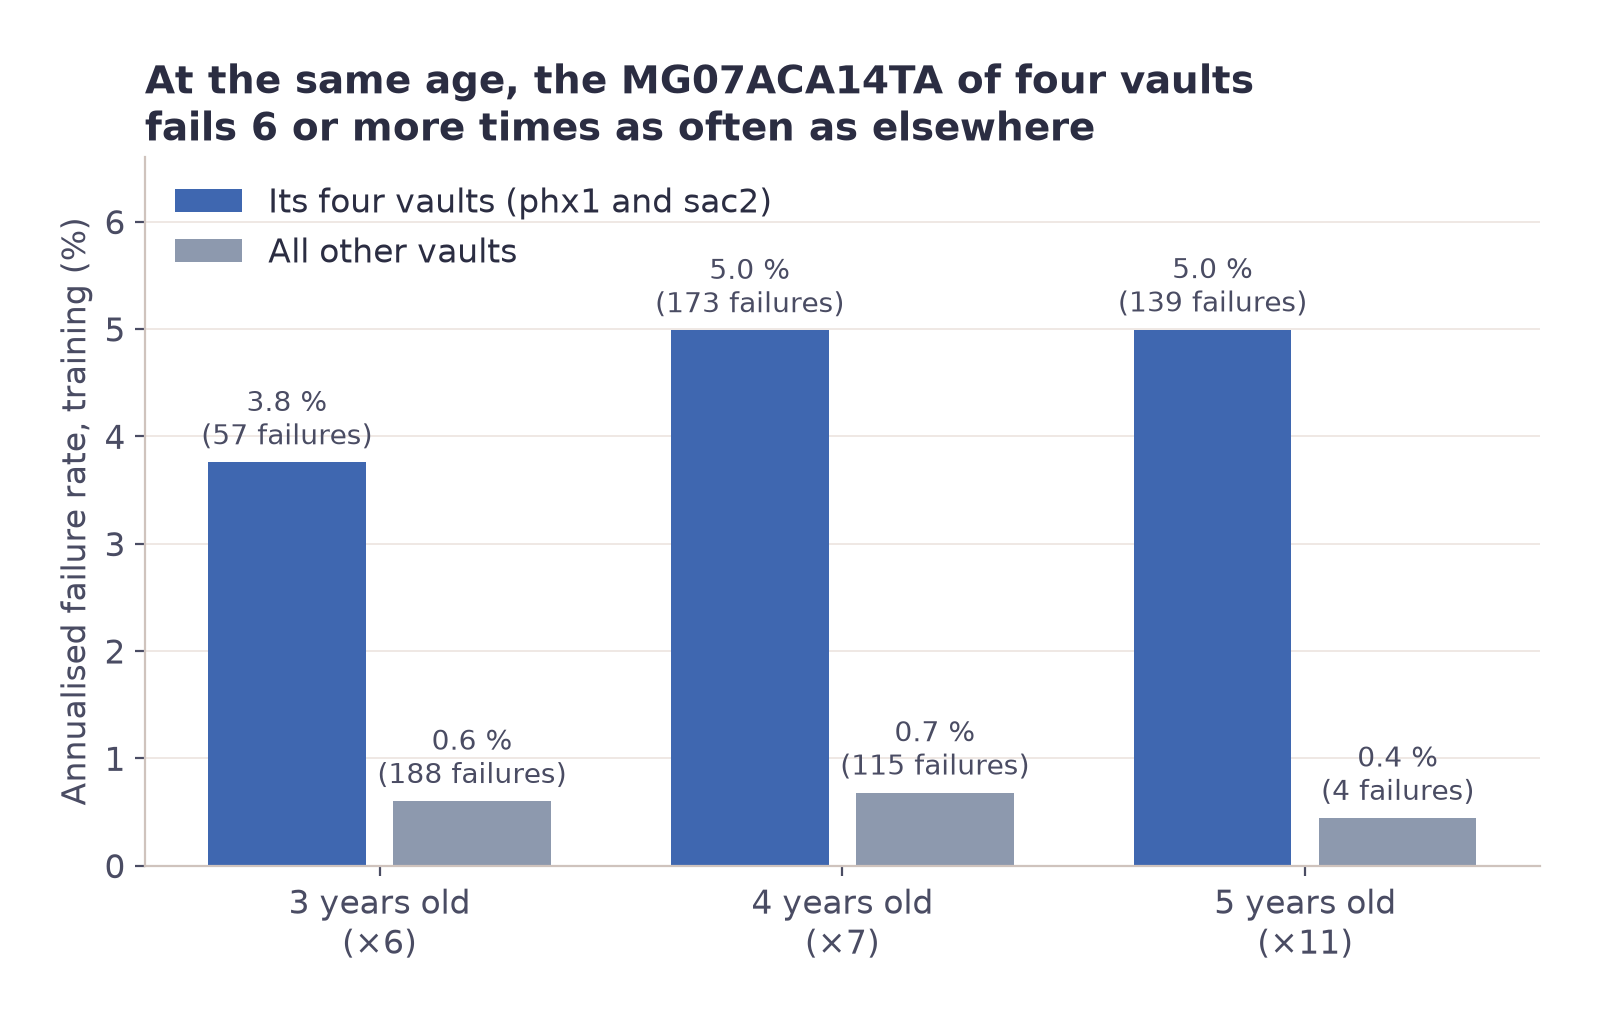

In [8]:
ages = nb.batch_by_age(con)
nb.plot_batch_by_age(ages)

**What we see**

- At 3 and 4 years old, these drives fail 6 to 7 times as often as drives of the same model and age elsewhere
  (3.8 % against 0.6 %, 5.0 % against 0.7 % a year). At 5 years the gap is larger, but there are only 4 failures
  elsewhere.
- So the vaults that fail too much hold groups of drives of one model that fail too much, most likely bad batches.
  The model does not see the batch; the vault could stand in for it while the batch stays there. Whether that helps
  is what the ablation measures.

## 5 · Ablation: the v1 with and without the vault

An ablation compares the same model with and without one input. Everything else is the v1: the same training sample
rows, the same 131 variables, the same search of 10 combinations, the same evaluation per drive life, comparisons A
and B against the three rules, and a working threshold fixed in validation (B against the 30-day rule).

> **Decision**: the vault enters as a category, like the drive model in the v1: vaults with at least 10 training
> failures get their own code; the rest, and vaults never seen in training, share "otros".
>
> **Why**: a category tells the model which vault a drive is in, not how much that vault failed. Vaults with few
> failures are grouped so that the model does not learn their accidents.
>
> **Discarded**: the vault as a number, its failure rate in training. Each drive's own failure would be inside its
> vault's number: a leak.

In [9]:
nb.show_vault_codes()

Vaults with their own code: 208 of 317, with 8,245 of 8,779 training failures; the rest, and vaults never seen in training, are 'otros'.


> **Decision**: decide with validation, then measure test once.
>
> **Why**: as in the v1, test must not choose anything. The decision (keep the v1 unless the vault clearly helps)
> was taken on validation, before test was opened.

The table gives both models in validation and test: comparison A against each rule (failures detected with as many
false alarms as the rule), comparison B (false alarms to detect as many failures as the rule), the working
threshold and PR-AUC. The last column is the difference in test.

In [10]:
results = nb.ablation_results()
nb.show_ablation(results)

,validation: v1,validation: with the vault,test: v1,test: with the vault,test: difference
measure,,,,,
"A: Static rule, failures detected","1,608","1,615","2,121","2,120",-1
"A: 7-day rule, failures detected","1,530","1,529","1,992","1,984",-8
"A: 30-day rule, failures detected","1,534","1,533","2,001","1,993",-8
"B: Static rule, false alarms","13,644","14,194","20,586","20,331",-255
"B: 7-day rule, false alarms","3,694","3,634","4,262","4,470",+208
"B: 30-day rule, false alarms","6,231","6,250","6,428","6,387",-41
"Working threshold, failures detected","1,401","1,401","1,778","1,784",+6
"Working threshold, false alarms","6,231","6,250","6,483","6,546",+63
PR-AUC per drive-day,0.1182,0.1196,0.1045,0.1023,-0.0022


The figure draws comparison A, the main one, in both periods.

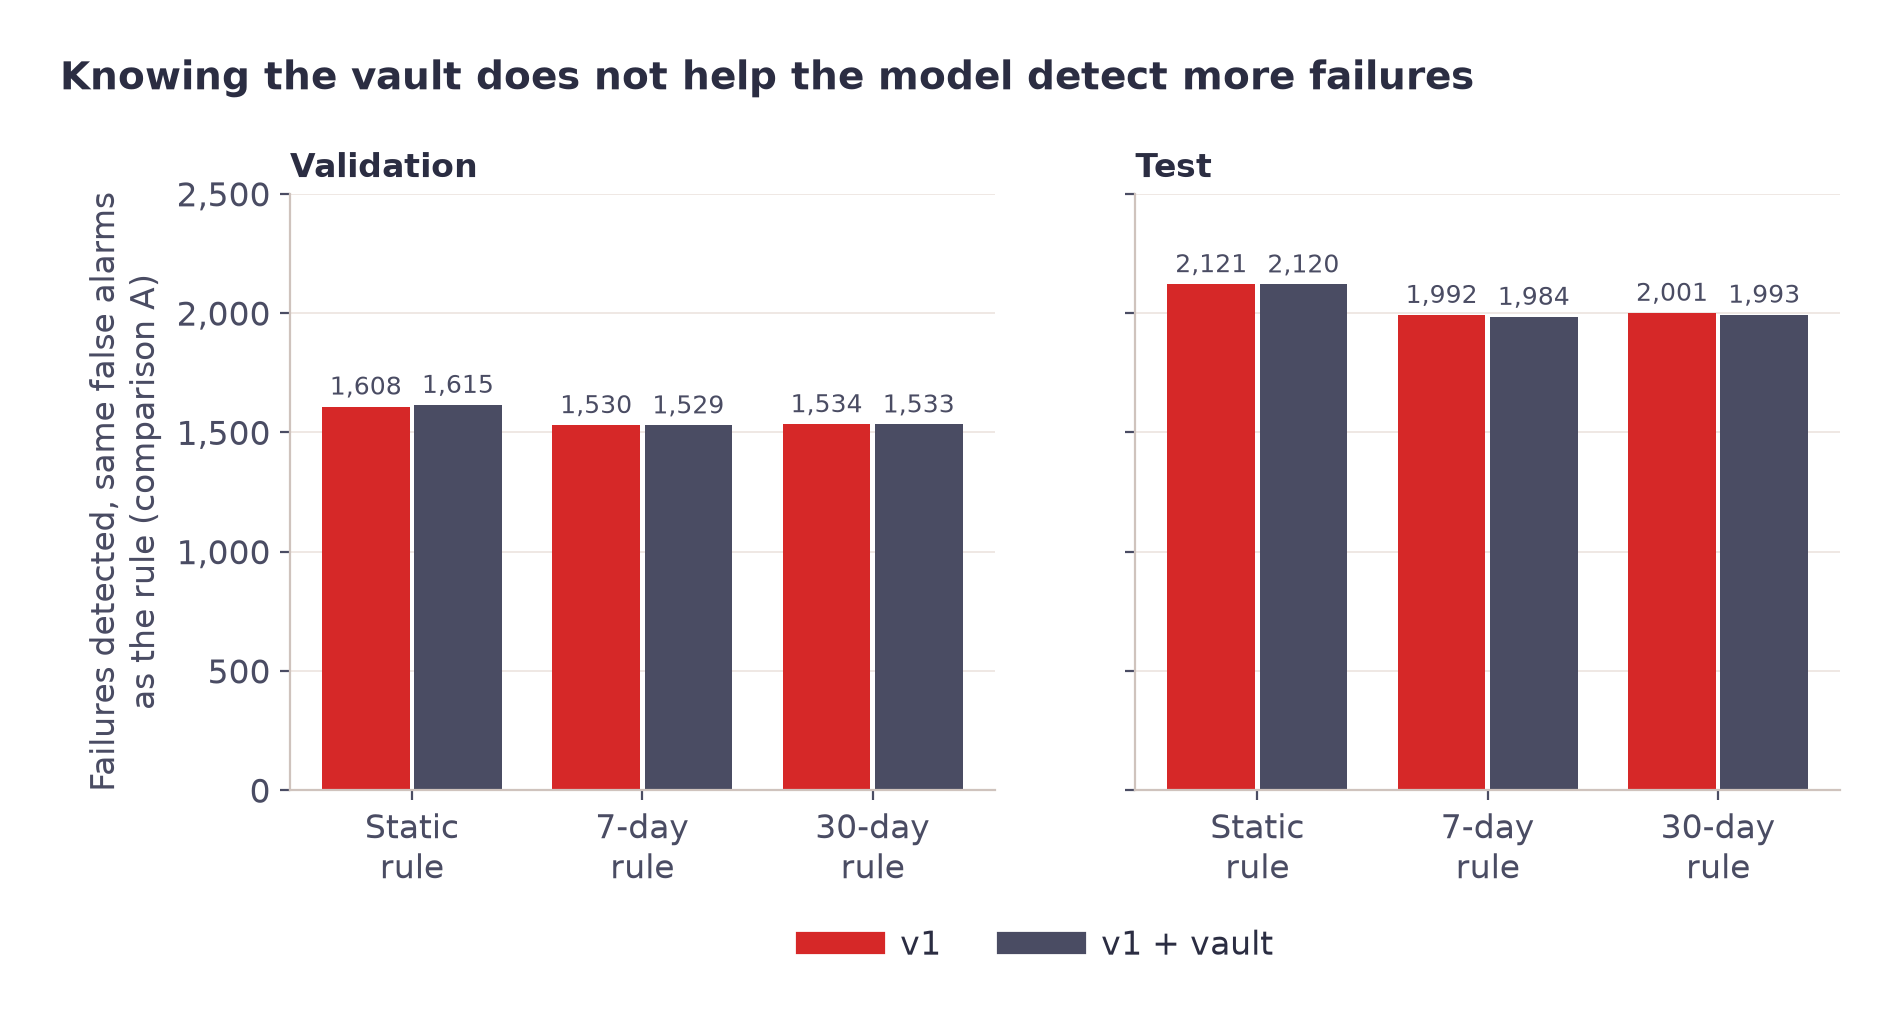

In [11]:
nb.plot_ablation(results)

**What we see**

- The two models are practically the same in both periods. In A, they differ by 1 to 8 failures out of 1,933 in
  validation and 2,552 in test; in B, the vault model has fewer false alarms against some rules and more against
  others.
- In test, the vault model is if anything slightly worse (PR-AUC 0.102 against 0.104). The decision taken on
  validation stands: location does not enter the model, and the v1 stays.

Why does the vault not help, if the vaults of the bad batches fail more? The table splits the failures and false
alarms of each period by vault group, each model at its own working threshold.

In [12]:
nb.show_by_vault_group()

**What we see**

- The vaults of the bad batches keep failing more: 341 of the 1,933 failures of validation (17.6 %) and 455 of the
  2,552 of test (17.8 %), with about 7 % of the healthy drive lives.
- The v1 already detects 86.5 % and 82.2 % of those failures, more than its average (72.5 % and 69.7 %), without
  knowing where they are: these drives warn through S.M.A.R.T. before failing.
- Knowing the vault adds 3 and 9 detected failures, at the cost of 86 and 80 more false alarms.

**Conclusion.** In these data, the differences between vaults come from the drives in them (batches), not from the
place, and knowing the location adds nothing to the model that the S.M.A.R.T. attributes do not already tell it.

**Limits.**
1. Backblaze's datacenters are similar, climate-controlled rooms; in places with real differences of heat or
   vibration, location could matter.
2. Pods and slots could not be studied well: about 8,800 training failures for 6,340 pods, too few per pod.
3. "Adds nothing to the model" is not "has no influence": a problem of the site that shows up in S.M.A.R.T. is
   already caught through it, and location could still matter for other questions, such as where to put new drives.

## Takeaways

- Datacenters differ in raw failure rate (twice as much in sac2 as in iad1), but almost all of it is their drive
  models: once those are accounted for, they stay within about ±10 %.
- No shortcut: vaults that are emptied do not fail more, and their failures do not pile up before they empty.
- Some vaults fail far more than chance allows, and the same ones in both training years. The excess comes from one
  drive model per vault, normal elsewhere and also at the same age: bad batches, not the place.
- Given the vault, the model does not improve in validation or in test. The v1 already detects more than 80 % of the
  failures of those batches through S.M.A.R.T., so the v1 model stays as it is.

Next: v3, a calibrated score that alerts again when a reviewed drive gets worse.